<a href="https://colab.research.google.com/github/PedroMecca/ActivityLifeCicleCompose/blob/master/Trabalho2_Recomendador_Criticos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabalho 2 — Recomendador de filmes por perfil de crítico
**PLN tradicional + IA pré-treinada (apenas na etapa final)**

**Ideia:** a partir do *texto* das críticas, prever se cada crítica é positiva (*Fresh*) ou negativa (*Rotten*),
descobrir de quais **gêneros** cada crítico gosta mais (ou menos) do que a própria média dele e, com isso,
**recomendar filmes** que ele ainda não avaliou. No final, uma IA pré-treinada (Hugging Face) entra em dois pontos:
(1) como segundo "avaliador" de sentimento para comparar com o modelo tradicional e (2) para escrever em linguagem
natural o perfil do crítico.

```
Corpus (Trabalho 1)
   └─► Processamento (limpeza, tokenização, stopwords, lematização)
         └─► TF-IDF ─► Classificador (Regressão Logística)  ◄── baseline + comparações
               └─► sentimento previsto de cada crítica
                     └─► perfil de gêneros do crítico ─► ranking de filmes
                           └─► [IA] DistilBERT (comparação / híbrido)  +  Flan-T5 (texto do perfil)
```

| Requisito do trabalho | Onde está neste notebook |
|---|---|
| Etapa 1 — Corpus | Seção 2 |
| Etapa 2 — Processamento | Seção 3 |
| Etapa 3 — Modelo principal (classificação) | Seções 4 e 6 |
| Etapa 4 — Avaliação (métricas, matriz de confusão, erros, baseline) | Seções 5 e 6 |
| Etapa 5 — Visualizações (8 figuras, salvas em `Trabalho2/resultados/`) | Seções 2 a 6 |
| Etapa 6 — Componente contemporâneo (Hugging Face) | Seção 7 |

> **Regra do trabalho:** a IA não substitui as etapas tradicionais. Aqui ela só **compara** (DistilBERT) e **apresenta**
> (Flan-T5), sempre em cima de números calculados pelo pipeline tradicional.

**Como rodar:** `Ambiente de execução → Executar tudo`. Recomendado usar GPU (T4) para a Seção 7 ficar rápida,
mas funciona na CPU (só demora alguns minutos a mais).

## 1. Configuração do ambiente

In [1]:
# [requer-colab] instalação de dependências (as versões estão no requirements.txt do repositório)
!pip -q install scikit-learn nltk spacy seaborn transformers sentencepiece accelerate
!python -m spacy download en_core_web_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import json
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import spearmanr

import nltk
try:
    import nltk.pathsec
    nltk.pathsec.ALLOW_PROXIED_FETCH = True   # necessário no Colab (saída de rede via proxy)
except Exception:
    pass
for pacote in ["punkt", "punkt_tab", "stopwords"]:
    nltk.download(pacote, quiet=True)
from nltk.corpus import stopwords

import spacy
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 160)

SEED = 42
raiz = Path("Trabalho2")
for pasta in ["dados", "resultados"]:
    (raiz / pasta).mkdir(parents=True, exist_ok=True)

nlp_en = spacy.load("en_core_web_sm", disable=["parser", "ner"])


def salvar_figura(fig, nome):
    fig.savefig(raiz / "resultados" / nome, dpi=150, bbox_inches="tight")


print("Ambiente pronto.")

Ambiente pronto.


## 2. Etapa 1 — Corpus

**Origem:** o corpus é o que construímos no **Trabalho 1**: críticas de filmes do Rotten Tomatoes (dataset público do Kaggle
`stefanoleone992/rotten-tomatoes-movies-and-critic-reviews-dataset`), unidas à tabela de filmes (gêneros, notas), limpas,
sem duplicatas e **amostradas de forma balanceada** (12 mil *Fresh* + 12 mil *Rotten*).

**Acesso aos dados:** a célula abaixo tenta baixar o arquivo `corpus_reviews_processado.csv` direto do repositório do
Trabalho 1 no GitHub. Se não encontrar, ela pede o upload do arquivo (ele está na pasta `dados_processados` do Trabalho 1).

In [3]:
URLS_CORPUS = [
    "https://raw.githubusercontent.com/PedroMecca/trabalho1-corpus-rotten-tomatoes/main/CorpusRottenTomatoes/dados_processados/corpus_reviews_processado.csv",
    "https://raw.githubusercontent.com/PedroMecca/trabalho1-corpus-rotten-tomatoes/main/dados_processados/corpus_reviews_processado.csv",
    "https://raw.githubusercontent.com/PedroMecca/trabalho1-corpus-rotten-tomatoes/main/corpus_reviews_processado.csv",
]
caminho_local = raiz / "dados" / "corpus_reviews_processado.csv"


def carregar_corpus():
    if caminho_local.exists():
        return pd.read_csv(caminho_local)
    for url in URLS_CORPUS:
        try:
            d = pd.read_csv(url)
            print("Corpus carregado de:", url)
            d.to_csv(caminho_local, index=False)
            return d
        except Exception:
            print("Não encontrei em:", url.split("main/")[1])
    from google.colab import files   # [requer-colab]
    print("Faça upload do corpus_reviews_processado.csv (gerado no Trabalho 1):")
    enviado = files.upload()
    d = pd.read_csv(list(enviado.keys())[0])
    d.to_csv(caminho_local, index=False)
    return d


df = carregar_corpus()

colunas_necessarias = ["review_content", "review_type", "genres", "critic_name", "movie_title",
                       "rotten_tomatoes_link", "tomatometer_rating"]
faltando = [c for c in colunas_necessarias if c not in df.columns]
assert not faltando, f"Colunas ausentes no CSV: {faltando}"

df = df.dropna(subset=["review_content", "review_type", "genres"]).reset_index(drop=True)
df["n_palavras"] = df["review_content"].str.split().str.len()
print("Formato do corpus:", df.shape)

Não encontrei em: CorpusRottenTomatoes/dados_processados/corpus_reviews_processado.csv
Não encontrei em: dados_processados/corpus_reviews_processado.csv
Não encontrei em: corpus_reviews_processado.csv
Faça upload do corpus_reviews_processado.csv (gerado no Trabalho 1):


Saving corpus_reviews_processado.csv to corpus_reviews_processado.csv
Formato do corpus: (23999, 19)


In [4]:
print(f"Críticas (documentos)      : {len(df):,}")
print(f"Filmes distintos           : {df['rotten_tomatoes_link'].nunique():,}")
print(f"Críticos distintos         : {df['critic_name'].nunique():,}")
print(f"Críticas sem nome de crítico: {df['critic_name'].isna().sum():,}")
print(f"Palavras por crítica (média): {df['n_palavras'].mean():.1f}  (mediana {df['n_palavras'].median():.0f})")
print()
display(df[["review_content", "review_type", "genres", "critic_name", "movie_title"]].sample(5, random_state=1))

Críticas (documentos)      : 23,999
Filmes distintos           : 9,047
Críticos distintos         : 3,242
Críticas sem nome de crítico: 211
Palavras por crítica (média): 21.4  (mediana 21)



,review_content,review_type,genres,critic_name,movie_title
8507,"The complexity, though, is reduced by caricaturing the Armitage family and their guests as unfeeling monsters[.]",Rotten,"Horror, Mystery & Suspense",CJ Sheu,Get Out
13817,[Director] LeMay earns points for his balanced presentation of key figures on both sides.,Fresh,"Documentary, Special Interest",Joe Leydon,Desert Bayou
8373,"Divergent suffers in comparison to Hunger Games. But when judged alone, Divergent makes a strong case for the entertainment value of an empowered young fema...",Fresh,"Action & Adventure, Science Fiction & Fantasy",Kathi Maio,Divergent
15577,"A deadly, desert-set game of cat and mouse that is tired and beyond plausibility.",Rotten,Mystery & Suspense,Brad Wheeler,Beyond The Reach
22427,"All these years on from its original release, King Kong still has a great claim to being the eighth wonder of the world.",Fresh,"Action & Adventure, Classics, Horror",Film4 Staff,King Kong


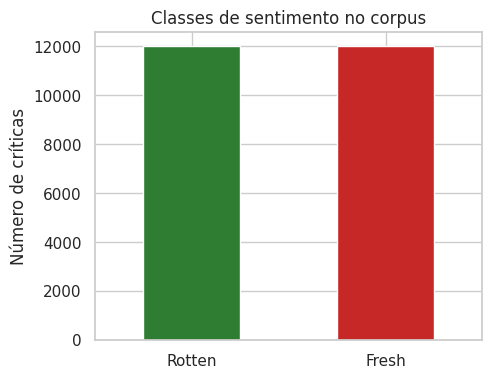

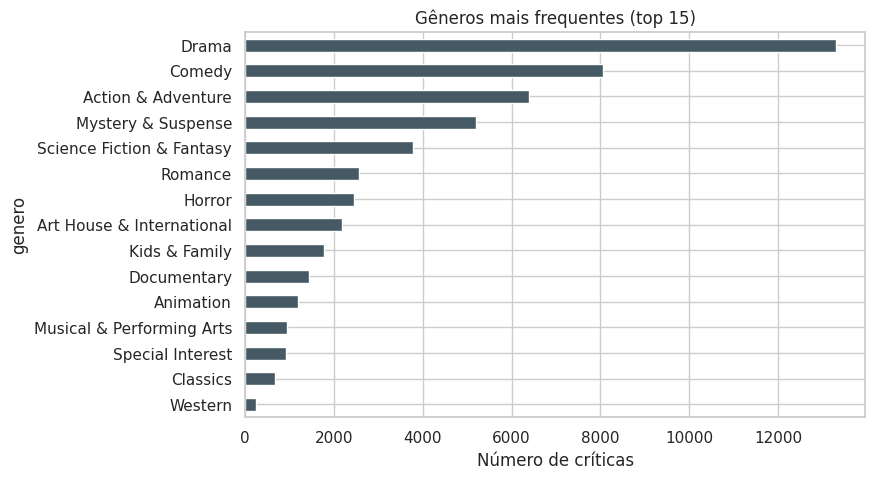

In [5]:
# Visualização 1 — distribuição das classes
fig, ax = plt.subplots(figsize=(5, 4))
df["review_type"].value_counts().plot(kind="bar", color=["#2e7d32", "#c62828"], ax=ax)
ax.set_title("Classes de sentimento no corpus")
ax.set_xlabel("")
ax.set_ylabel("Número de críticas")
plt.xticks(rotation=0)
salvar_figura(fig, "v1_classes.png")
plt.show()


def explodir_generos(d):
    # um filme pode ter vários gêneros separados por vírgula
    e = d.assign(genero=d["genres"].str.split(","))
    e = e.explode("genero")
    e["genero"] = e["genero"].str.strip()
    return e


# Visualização 2 — gêneros mais frequentes
contagem_generos = explodir_generos(df)["genero"].value_counts().head(15)
fig, ax = plt.subplots(figsize=(8, 5))
contagem_generos.sort_values().plot(kind="barh", color="#455a64", ax=ax)
ax.set_title("Gêneros mais frequentes (top 15)")
ax.set_xlabel("Número de críticas")
salvar_figura(fig, "v2_generos.png")
plt.show()

### 2.1 Vieses e limitações do corpus

- **Críticos profissionais**, não o público geral; os textos são **trechos curtos** (~20 palavras), mais "frases-síntese" do que resenhas completas.
- **Amostra balanceada artificialmente (50/50).** No dataset original há bem mais *Fresh* do que *Rotten* (≈64% *Fresh* depois da limpeza no Trabalho 1);
  as métricas valem para o cenário balanceado, não para a proporção real.
- **O rótulo não vem do texto:** *Fresh/Rotten* vem da nota que o crítico deu. Uma crítica pode ter tom positivo e rótulo *Rotten* (e vice-versa),
  então existe **ruído de rótulo** que limita a acurácia de qualquer modelo.
- **Gêneros concentrados** (Drama e Comédia dominam) e **multirrótulo** (um filme tem vários gêneros).
- **Poucas críticas por crítico:** só dá para montar perfil confiável para quem tem um mínimo de críticas na amostra (usamos ≥ 20) e usamos suavização estatística.
- **Catálogo restrito:** só conseguimos recomendar filmes que aparecem na amostra, e o "usuário" aqui é um **crítico**, não uma pessoa real usando o sistema.

## 3. Etapa 2 — Processamento (versão 2)

Reaproveitamos o pipeline do Trabalho 1, mas corrigimos duas limitações que identificamos lá:

1. **Negação:** a lista de stopwords do NLTK remove *not/no/nor*, o que transforma "not good" em "good". Agora **mantemos as palavras de negação**
   e expandimos contrações (*don't → do not*).
2. **Ordem:** antes lematizávamos *depois* de remover stopwords (o spaCy perdia o contexto da frase). Agora **tokenizamos e lematizamos a frase inteira** e só depois filtramos.

| Técnica | Justificativa |
|---|---|
| Limpeza + minúsculas | remove ruído (HTML, links, pontuação) e reduz o vocabulário |
| Expansão de contrações | preserva a negação ("n't" → "not") |
| Tokenização (spaCy) | separa o texto em palavras |
| Stopwords (NLTK, **sem as negações**) | tira palavras funcionais, mas mantém as que invertem sentimento |
| Lematização (spaCy) | `loved/loves → love`, reduz esparsidade |
| TF-IDF com unigramas e bigramas | pondera palavras discriminativas; bigramas capturam "not good" |

In [6]:
NEGACOES = {"no", "not", "nor", "never", "neither", "nothing", "nobody", "none", "nowhere",
            "hardly", "barely", "without"}
STOP = set(stopwords.words("english")) - NEGACOES


def limpar_texto(t):
    t = re.sub(r"<[^>]+>", " ", t)                    # HTML
    t = re.sub(r"http\S+|www\.\S+", " ", t)           # links
    t = t.lower()
    t = re.sub(r"\bcan['’]t\b", "can not", t)         # contrações com negação
    t = re.sub(r"\bwon['’]t\b", "will not", t)
    t = re.sub(r"n['’]t\b", " not", t)
    t = re.sub(r"[^a-z\s]", " ", t)                   # só letras
    return re.sub(r"\s+", " ", t).strip()


def processar_textos(textos, batch_size=512):
    # limpeza -> tokenização + lematização (spaCy, frase inteira) -> filtro de stopwords
    limpos = [limpar_texto(t) for t in textos]
    saida = []
    for doc in nlp_en.pipe(limpos, batch_size=batch_size):
        tokens = []
        for tok in doc:
            if tok.is_space or tok.text in STOP:
                continue
            if len(tok.text) < 3 and tok.text not in NEGACOES:
                continue
            lema = tok.lemma_.lower().strip()
            if lema:
                tokens.append(lema)
        saida.append(" ".join(tokens))
    return saida


# Demonstração passo a passo
amostra = [
    "This isn't a bad movie, but it doesn't quite work either.",
    "A dazzling, beautifully acted drama that I loved.",
    "Not funny, not scary, and never surprising.",
]
for original, final in zip(amostra, processar_textos(amostra)):
    limpo = limpar_texto(original)
    print("Original   :", original)
    print("Limpo      :", limpo)
    print("Tokens     :", [t.text for t in nlp_en.make_doc(limpo)])
    print("Processado :", final)
    print()

Original   : This isn't a bad movie, but it doesn't quite work either.
Limpo      : this is not a bad movie but it does not quite work either
Tokens     : ['this', 'is', 'not', 'a', 'bad', 'movie', 'but', 'it', 'does', 'not', 'quite', 'work', 'either']
Processado : not bad movie not quite work either

Original   : A dazzling, beautifully acted drama that I loved.
Limpo      : a dazzling beautifully acted drama that i loved
Tokens     : ['a', 'dazzling', 'beautifully', 'acted', 'drama', 'that', 'i', 'loved']
Processado : dazzle beautifully act drama love

Original   : Not funny, not scary, and never surprising.
Limpo      : not funny not scary and never surprising
Tokens     : ['not', 'funny', 'not', 'scary', 'and', 'never', 'surprising']
Processado : not funny not scary never surprising



In [7]:
t0 = time.time()
df["texto_v2"] = processar_textos(df["review_content"].tolist())
print(f"Processados {len(df):,} documentos em {time.time() - t0:.0f}s")
print("Documentos que ficaram vazios:", (df["texto_v2"].str.len() == 0).sum(), "(mantidos; viram vetor zero no TF-IDF)")

df.to_csv(raiz / "dados" / "corpus_t2_processado.csv", index=False)
display(df[["review_content", "texto_v2"]].head(4))

Processados 23,999 documentos em 31s
Documentos que ficaram vazios: 0 (mantidos; viram vetor zero no TF-IDF)


,review_content,texto_v2
0,"Once the wilted satire of Jason Micallef's script is stripped away, what's left is a generally amusing competition comedy.",wilt satire jason micallef script strip away leave generally amusing competition comedy
1,"if there was ever a film to end a career, Tideland is it.",ever film end career tideland
2,This is an awfully polite movie about a man who was anything but.,awfully polite movie man anything
3,"The movie creaks along to its happy ending, ultimately suffocating under way too many layers of brocade, velvet, and ostrich feathers.",movie creak along happy ending ultimately suffocate way many layer brocade velvet ostrich feather


## 4. Etapa 3 — Modelo principal: classificação de sentimento

**Abordagem:** classificação supervisionada (*Fresh × Rotten*) com **TF-IDF + Regressão Logística**: simples, rápida e interpretável.
Usamos a **mesma divisão 80/20 estratificada do Trabalho 1** (`random_state=42`), para comparar com o resultado anterior.

Modelos comparados:
- **Baseline:** classificador que sempre responde a classe mais comum (`DummyClassifier`);
- **LR + TF-IDF (Trabalho 1):** texto do pipeline antigo (se a coluna `texto_processado` existir no CSV);
- **LR + TF-IDF (v2):** pipeline novo, com negação;
- **Naive Bayes (ComplementNB) + TF-IDF (v2):** outro modelo clássico para comparação.

In [8]:
y = df["review_type"]
idx_treino, idx_teste = train_test_split(df.index, test_size=0.2, stratify=y, random_state=SEED)
y_treino, y_teste = y.loc[idx_treino], y.loc[idx_teste]
print("Treino:", len(idx_treino), "| Teste:", len(idx_teste))
print(y_teste.value_counts().to_dict())


def novo_vetorizador():
    return TfidfVectorizer(max_features=20_000, ngram_range=(1, 2), min_df=3)


def treinar_lr(coluna):
    vet = novo_vetorizador()
    Xtr = vet.fit_transform(df.loc[idx_treino, coluna].fillna(""))
    Xte = vet.transform(df.loc[idx_teste, coluna].fillna(""))
    modelo = LogisticRegression(max_iter=1000, C=1.0, random_state=SEED)
    modelo.fit(Xtr, y_treino)
    return vet, modelo, Xtr, Xte


metricas, previsoes = [], {}
y_teste_bin = (y_teste == "Fresh").astype(int).values


def registrar(nome, y_pred, p_fresh):
    y_pred = np.asarray(y_pred)
    metricas.append({
        "modelo": nome,
        "acuracia": accuracy_score(y_teste, y_pred),
        "f1_macro": f1_score(y_teste, y_pred, average="macro"),
        "auc": roc_auc_score(y_teste_bin, p_fresh),
    })
    previsoes[nome] = (y_pred, np.asarray(p_fresh))


# --- modelo principal (v2)
NOME_V2 = "LR + TF-IDF (v2, com negação)"
vet_v2, modelo_v2, Xtr_v2, Xte_v2 = treinar_lr("texto_v2")
IDX_FRESH = list(modelo_v2.classes_).index("Fresh")

# --- baseline
baseline = DummyClassifier(strategy="most_frequent").fit(Xtr_v2, y_treino)
registrar("Baseline (classe mais comum)", baseline.predict(Xte_v2), baseline.predict_proba(Xte_v2)[:, IDX_FRESH])
print("O baseline sempre responde:", y_treino.value_counts().idxmax())

# --- pipeline do Trabalho 1 (se disponível)
NOME_T1 = "LR + TF-IDF (Trabalho 1)"
if "texto_processado" in df.columns:
    vet_t1, modelo_t1, Xtr_t1, Xte_t1 = treinar_lr("texto_processado")
    registrar(NOME_T1, modelo_t1.predict(Xte_t1), modelo_t1.predict_proba(Xte_t1)[:, IDX_FRESH])
else:
    print("Coluna 'texto_processado' não encontrada: comparação com o pipeline do Trabalho 1 foi pulada.")

# --- v2
registrar(NOME_V2, modelo_v2.predict(Xte_v2), modelo_v2.predict_proba(Xte_v2)[:, IDX_FRESH])

# --- Naive Bayes
nb = ComplementNB().fit(Xtr_v2, y_treino)
registrar("ComplementNB + TF-IDF (v2)", nb.predict(Xte_v2), nb.predict_proba(Xte_v2)[:, IDX_FRESH])

display(pd.DataFrame(metricas).round(4))

Treino: 19199 | Teste: 4800
{'Fresh': 2400, 'Rotten': 2400}
O baseline sempre responde: Rotten


,modelo,acuracia,f1_macro,auc
0,Baseline (classe mais comum),0.5000,0.3333,0.5000
1,LR + TF-IDF (Trabalho 1),0.7540,0.7539,0.8315
2,"LR + TF-IDF (v2, com negação)",0.7610,0.7610,0.8391
3,ComplementNB + TF-IDF (v2),0.7638,0.7637,0.8406


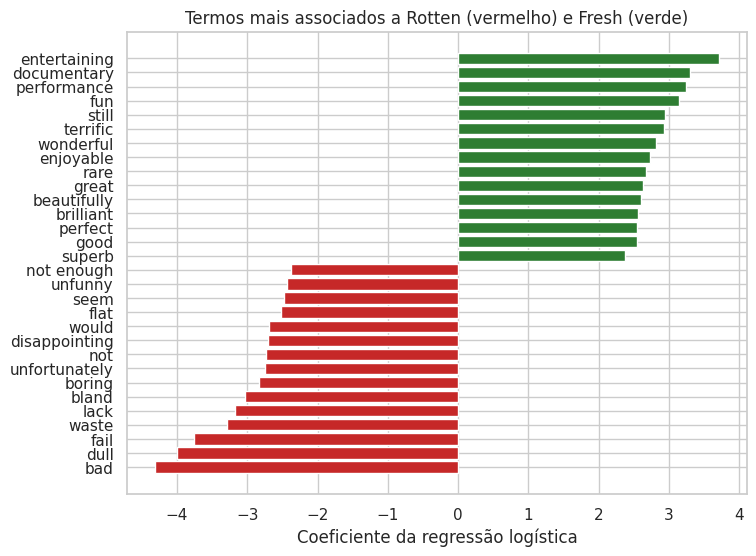

Bigramas de negação com maior peso (positivo = Fresh):
[('not enough', np.float64(-2.38)), ('not funny', np.float64(-2.25)), ('never quite', np.float64(-1.67)), ('not even', np.float64(-1.61)), ('never bore', np.float64(1.25)), ('never less', np.float64(1.23)), ('not quite', np.float64(-1.23)), ('not miss', np.float64(1.17)), ('never really', np.float64(-1.14)), ('not half', np.float64(1.14)), ('not great', np.float64(1.09)), ('never find', np.float64(-1.05))]


In [9]:
# Visualização 3 — termos que mais pesam para cada classe (interpretabilidade)
termos = np.array(vet_v2.get_feature_names_out())
coef = modelo_v2.coef_[0].copy()
if modelo_v2.classes_[1] != "Fresh":
    coef = -coef                      # agora coef positivo = puxa para Fresh

ordem = np.argsort(coef)
top_neg, top_pos = ordem[:15], ordem[-15:]
fig, ax = plt.subplots(figsize=(8, 6))
idx_plot = np.concatenate([top_neg, top_pos])
cores = ["#c62828"] * 15 + ["#2e7d32"] * 15
ax.barh(termos[idx_plot], coef[idx_plot], color=cores)
ax.set_title("Termos mais associados a Rotten (vermelho) e Fresh (verde)")
ax.set_xlabel("Coeficiente da regressão logística")
salvar_figura(fig, "v3_termos.png")
plt.show()

# Efeito da negação: bigramas "not ..." e o peso que o modelo deu a eles
neg_bigramas = [(t, round(c, 2)) for t, c in zip(termos, coef) if t.startswith(("not ", "never ", "no "))]
neg_bigramas = sorted(neg_bigramas, key=lambda x: abs(x[1]), reverse=True)[:12]
print("Bigramas de negação com maior peso (positivo = Fresh):")
print(neg_bigramas)

## 5. Etapa 4 — Avaliação

              precision    recall  f1-score   support

       Fresh      0.763     0.757     0.760      2400
      Rotten      0.759     0.765     0.762      2400

    accuracy                          0.761      4800
   macro avg      0.761     0.761     0.761      4800
weighted avg      0.761     0.761     0.761      4800



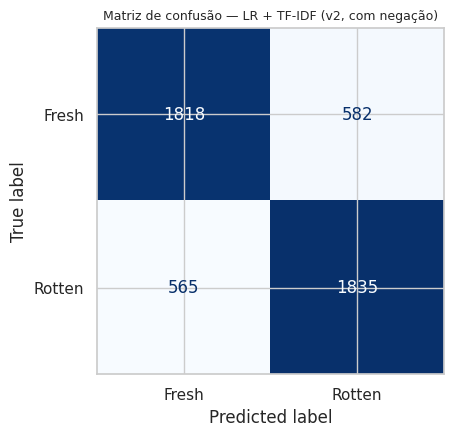

In [10]:
pred_v2, p_v2 = previsoes[NOME_V2]
print(classification_report(y_teste, pred_v2, digits=3))

# Visualização 4 — matriz de confusão
cm = confusion_matrix(y_teste, pred_v2, labels=["Fresh", "Rotten"])
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["Fresh", "Rotten"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusão — " + NOME_V2, fontsize=9)
salvar_figura(fig, "v4_matriz_confusao.png")
plt.show()

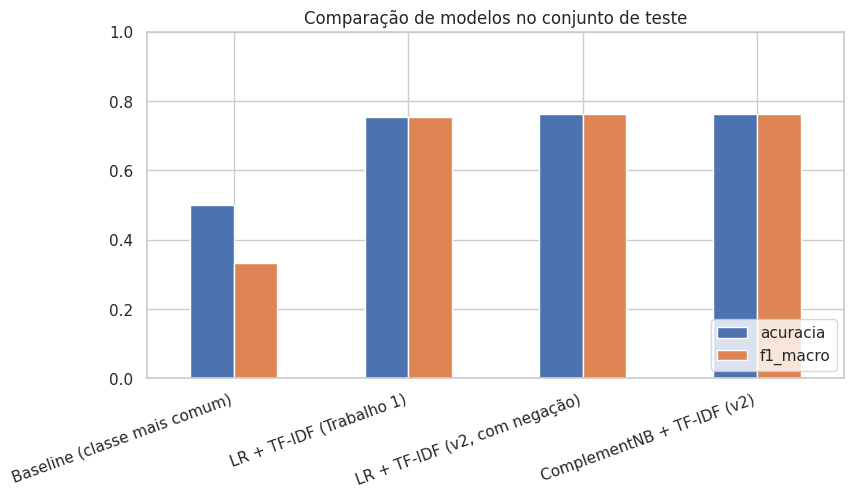

,acuracia,f1_macro,auc
modelo,,,
Baseline (classe mais comum),0.5000,0.3333,0.5000
LR + TF-IDF (Trabalho 1),0.7540,0.7539,0.8315
"LR + TF-IDF (v2, com negação)",0.7610,0.7610,0.8391
ComplementNB + TF-IDF (v2),0.7638,0.7637,0.8406


In [11]:
# Visualização 5 — comparação de modelos
tabela_metricas = pd.DataFrame(metricas).set_index("modelo")
fig, ax = plt.subplots(figsize=(9, 4.5))
tabela_metricas[["acuracia", "f1_macro"]].plot(kind="bar", ax=ax)
ax.set_ylim(0, 1)
ax.set_title("Comparação de modelos no conjunto de teste")
ax.set_xlabel("")
plt.xticks(rotation=20, ha="right")
ax.legend(loc="lower right")
salvar_figura(fig, "v5_comparacao_modelos.png")
plt.show()
display(tabela_metricas.round(4))

### 5.1 Análise dos erros

Erros: 1147 de 4800 (23.9%)

Taxa de erro com/sem negação no texto:
tem_negacao
sem negação    0.230
com negação    0.264
Name: erro, dtype: float64


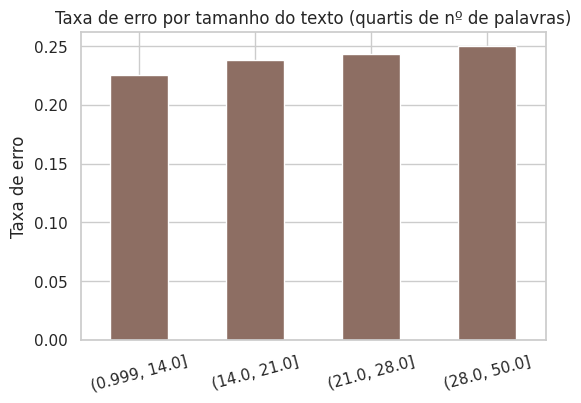


Erros em que o modelo estava mais confiante (texto original):


,review_content,review_type,previsto,p_fresh
17915,"It is not a bad movie at all, nor is it graceful.",Fresh,Rotten,0.059
23536,There's no sleeping tonight,Fresh,Rotten,0.083
8614,"A goofy, gonzo thrill ride, Vengeance is a bad movie sequel so bad it's good -- a bad movie that's almost a great bad movie.",Fresh,Rotten,0.083
12326,"If the best westerns have always been, in some way, studies of contemporary manhood, it's worrisome to think about what this Magnificent Seven says about me...",Rotten,Fresh,0.916
23957,Everything could be sharper. It isn't dull.,Fresh,Rotten,0.090
5628,"""Endearingly clunky"" is what I would call it.",Fresh,Rotten,0.094
16038,"Bad Times At The El Royale is Tarantino Lite, but not as an insult.",Fresh,Rotten,0.101
13330,It's not a bad effort at all - and certainly a whole class above Ninja Turtles.,Fresh,Rotten,0.103


In [12]:
teste = df.loc[idx_teste, ["review_content", "review_type", "n_palavras"]].copy()
teste["previsto"] = pred_v2
teste["p_fresh"] = p_v2
teste["erro"] = teste["previsto"] != teste["review_type"]
print(f"Erros: {teste['erro'].sum()} de {len(teste)} ({teste['erro'].mean():.1%})")

# erro por tamanho do texto
teste["faixa_tamanho"] = pd.qcut(teste["n_palavras"], 4, duplicates="drop")
erro_tamanho = teste.groupby("faixa_tamanho")["erro"].mean()

# erro com e sem negação no texto original
regex_neg = r"n['’]t\b|\b(?:not|no|never|nothing|neither|nor)\b"
teste["tem_negacao"] = teste["review_content"].str.lower().str.contains(regex_neg, regex=True)
print("\nTaxa de erro com/sem negação no texto:")
print(teste.groupby("tem_negacao")["erro"].mean().round(3).rename({False: "sem negação", True: "com negação"}))

# Visualização 6 — erro por tamanho do texto
fig, ax = plt.subplots(figsize=(6, 4))
erro_tamanho.plot(kind="bar", color="#8d6e63", ax=ax)
ax.set_title("Taxa de erro por tamanho do texto (quartis de nº de palavras)")
ax.set_xlabel("")
ax.set_ylabel("Taxa de erro")
plt.xticks(rotation=15)
salvar_figura(fig, "v6_erro_por_tamanho.png")
plt.show()

# erros mais "confiantes" do modelo: ajudam a enxergar ruído de rótulo
erros = teste[teste["erro"]].copy()
erros["confianca"] = (erros["p_fresh"] - 0.5).abs()
print("\nErros em que o modelo estava mais confiante (texto original):")
display(erros.sort_values("confianca", ascending=False).head(8)[["review_content", "review_type", "previsto", "p_fresh"]].round(3))

**Como ler:** se o modelo erra com muita confiança em frases que *parecem* claramente positivas/negativas, isso indica **ruído de rótulo**
(a nota do crítico não bate com o tom do texto) e não necessariamente falha do modelo. Textos curtos e com ressalvas ("good cast, but…") também tendem a errar mais.

## 6. Aplicação — perfil de gêneros do crítico e recomendação de filmes

Aqui o classificador vira ferramenta. Passos:

1. **Sentimento previsto para todas as críticas** com validação cruzada (*out-of-fold*: cada crítica é prevista por um modelo que **não a viu** no treino).
   Isso simula o cenário real em que só temos o **texto** (sem o rótulo *Fresh/Rotten*).
2. **Perfil de gêneros:** para cada crítico, a taxa de críticas positivas por gênero, **suavizada** (puxada para a média do próprio crítico quando há poucas críticas):
   `afinidade = (positivas + k·média_do_crítico) / (n + k)`, com k = 5. O **lift** é `afinidade − média_do_crítico`:
   positivo = gosta *mais que o normal dele* desse gênero.
3. **Recomendação:** nota do filme = `(1 − w)·afinidade_média_dos_gêneros + w·tomatometer/100`, com w = 0,3, entre filmes que o crítico **ainda não avaliou**.
4. **Avaliação** da recomendação contra uma referência (ranking só por tomatometer) e checagem se o perfil montado com rótulos **previstos** se parece com o montado com rótulos **reais**.

In [13]:
pipe_oof = make_pipeline(novo_vetorizador(), LogisticRegression(max_iter=1000, random_state=SEED))
p_oof = cross_val_predict(pipe_oof, df["texto_v2"].fillna(""), y,
                          cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")
df["p_fresh_oof"] = p_oof[:, list(np.unique(y)).index("Fresh")]
df["rotulo_previsto"] = np.where(df["p_fresh_oof"] >= 0.5, "Fresh", "Rotten")
print(f"Acurácia out-of-fold (corpus inteiro): {(df['rotulo_previsto'] == y).mean():.3f}")

df_c = df.dropna(subset=["critic_name"]).copy()
MIN_CRITICAS = 20
contagem_criticos = df_c["critic_name"].value_counts()
criticos_elegiveis = contagem_criticos[contagem_criticos >= MIN_CRITICAS].index
print(f"Críticos com pelo menos {MIN_CRITICAS} críticas: {len(criticos_elegiveis)}")

Acurácia out-of-fold (corpus inteiro): 0.756
Críticos com pelo menos 20 críticas: 309


In [14]:
def perfil_generos(d, coluna="review_type", k=5):
    # perfil de gêneros de um crítico; coluna = 'review_type' (real) ou 'rotulo_previsto' (modelo)
    base = (d[coluna] == "Fresh").mean()
    e = explodir_generos(d)
    g = e.groupby("genero")[coluna].agg(n="size", fresh=lambda s: (s == "Fresh").sum())
    g["taxa_bruta"] = g["fresh"] / g["n"]
    g["afinidade"] = (g["fresh"] + k * base) / (g["n"] + k)
    g["lift"] = g["afinidade"] - base
    return g.sort_values("lift", ascending=False), base


catalogo = df.drop_duplicates("rotten_tomatoes_link")[["rotten_tomatoes_link", "movie_title", "genres", "tomatometer_rating"]].copy()
catalogo["tomatometer_rating"] = catalogo["tomatometer_rating"].fillna(catalogo["tomatometer_rating"].median())
print("Filmes no catálogo:", len(catalogo))


def recomendar_filmes(nome, coluna="review_type", top_n=5, peso_qualidade=0.3, k=5):
    d = df_c[df_c["critic_name"] == nome]
    perfil, base = perfil_generos(d, coluna, k)
    vistos = set(d["rotten_tomatoes_link"])
    cand = catalogo[~catalogo["rotten_tomatoes_link"].isin(vistos)].copy()
    cand["afinidade"] = cand["genres"].apply(
        lambda s: np.mean([perfil["afinidade"].get(g.strip(), base) for g in s.split(",")]))
    cand["score"] = (1 - peso_qualidade) * cand["afinidade"] + peso_qualidade * cand["tomatometer_rating"] / 100
    recs = cand.sort_values("score", ascending=False).head(top_n)
    return recs[["movie_title", "genres", "tomatometer_rating", "afinidade", "score"]], perfil, base


# teste rápido com o crítico que mais avaliou
critico_exemplo = contagem_criticos.index[0]
recs_exemplo, perfil_exemplo, base_exemplo = recomendar_filmes(critico_exemplo, coluna="rotulo_previsto")
print(f"Crítico: {critico_exemplo} | % de críticas positivas (previsto): {base_exemplo:.0%}")
display(perfil_exemplo[perfil_exemplo["n"] >= 5].round(3).head(6))
display(recs_exemplo.round(3))

Filmes no catálogo: 9047
Crítico: Frank Swietek | % de críticas positivas (previsto): 31%


,n,fresh,taxa_bruta,afinidade,lift
genero,,,,,
Art House & International,17,11,0.647,0.569,0.264
Documentary,6,4,0.667,0.503,0.197
Special Interest,6,4,0.667,0.503,0.197
Animation,7,4,0.571,0.461,0.155
Musical & Performing Arts,6,3,0.500,0.412,0.106
Comedy,54,21,0.389,0.382,0.076


,movie_title,genres,tomatometer_rating,afinidade,score
21923,United We Fan,"Art House & International, Documentary",100.0,0.536,0.675
7928,"Faces Places (Visages, villages)","Art House & International, Documentary",99.0,0.536,0.672
10102,Last Train Home,"Art House & International, Documentary, Special Interest",100.0,0.525,0.667
15227,Rio Breaks,"Art House & International, Documentary, Special Interest",100.0,0.525,0.667
21060,Modern Life (Profils paysans: la vie moderne),"Art House & International, Documentary, Special Interest",100.0,0.525,0.667


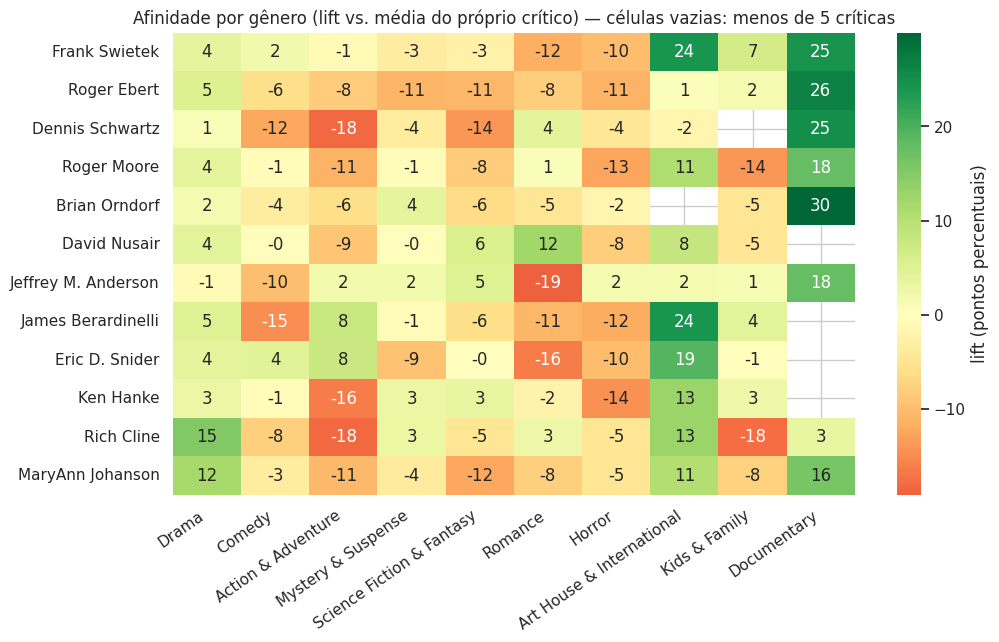

In [15]:
# Visualização 7 — mapa de calor: gêneros que cada crítico gosta mais (verde) ou menos (vermelho) que a própria média
top_criticos = contagem_criticos.head(12).index
top_generos = explodir_generos(df_c)["genero"].value_counts().head(10).index
mat = pd.DataFrame(index=top_criticos, columns=top_generos, dtype=float)
for nome in top_criticos:
    pf, _ = perfil_generos(df_c[df_c["critic_name"] == nome], "review_type")
    for gen in top_generos:
        if gen in pf.index and pf.loc[gen, "n"] >= 5:
            mat.loc[nome, gen] = pf.loc[gen, "lift"] * 100

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(mat, annot=True, fmt=".0f", cmap="RdYlGn", center=0, ax=ax, cbar_kws={"label": "lift (pontos percentuais)"})
ax.set_title("Afinidade por gênero (lift vs. média do próprio crítico) — células vazias: menos de 5 críticas")
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=35, ha="right")
salvar_figura(fig, "v7_mapa_afinidade.png")
plt.show()

Correlação de Spearman média entre perfil real e perfil previsto: 0.51  (309 críticos)


,perfil com rótulos reais,perfil com rótulos previstos
só tomatometer (referência),0.829,0.829
afinidade (gênero + tendência do crítico),0.633,0.592
só gênero (lift),0.582,0.555
combinado (afinidade + tomatometer),0.788,0.774


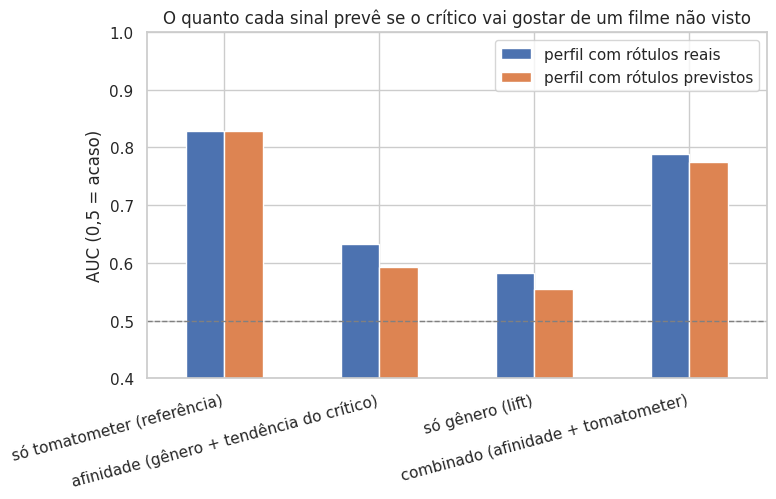

In [16]:
# (a) o perfil montado com rótulos PREVISTOS se parece com o montado com rótulos REAIS?
def correlacao_perfis(criticos, min_n=3):
    cs = []
    for nome in criticos:
        d = df_c[df_c["critic_name"] == nome]
        pr, _ = perfil_generos(d, "review_type")
        pp, _ = perfil_generos(d, "rotulo_previsto")
        pr = pr[pr["n"] >= min_n]
        j = pr[["lift"]].join(pp[["lift"]], lsuffix="_real", rsuffix="_prev", how="inner")
        if len(j) >= 4:
            cs.append(spearmanr(j["lift_real"], j["lift_prev"])[0])
    return np.array(cs)


cors = correlacao_perfis(criticos_elegiveis)
corr_media = float(np.nanmean(cors))
print(f"Correlação de Spearman média entre perfil real e perfil previsto: {corr_media:.2f}  ({len(cors)} críticos)")


# (b) a recomendação adiciona algo além da "qualidade global" do filme? (hold-out por crítico)
def avaliar_recomendador(coluna_rotulo, peso_qualidade=0.3, k=5, frac_teste=0.25):
    rng = np.random.RandomState(SEED)
    linhas = []
    for nome in criticos_elegiveis:
        d = df_c[df_c["critic_name"] == nome]
        perm = rng.permutation(len(d))
        n_te = max(3, int(len(d) * frac_teste))
        teste_c, treino_c = d.iloc[perm[:n_te]], d.iloc[perm[n_te:]]
        perfil, base = perfil_generos(treino_c, coluna_rotulo, k)
        for gens, tomato, real in zip(teste_c["genres"], teste_c["tomatometer_rating"], teste_c["review_type"]):
            afin = np.mean([perfil["afinidade"].get(g.strip(), base) for g in gens.split(",")])
            linhas.append({"real": int(real == "Fresh"), "tomatometer": tomato, "afinidade": afin, "lift": afin - base})
    r = pd.DataFrame(linhas)
    r["tomatometer"] = r["tomatometer"].fillna(r["tomatometer"].median())
    r["combinado"] = (1 - peso_qualidade) * r["afinidade"] + peso_qualidade * r["tomatometer"] / 100
    return {c: roc_auc_score(r["real"], r[c]) for c in ["tomatometer", "afinidade", "lift", "combinado"]}


auc_real = avaliar_recomendador("review_type")
auc_prev = avaliar_recomendador("rotulo_previsto")
tabela_rec = pd.DataFrame({"perfil com rótulos reais": auc_real, "perfil com rótulos previstos": auc_prev})
tabela_rec.index = ["só tomatometer (referência)", "afinidade (gênero + tendência do crítico)",
                    "só gênero (lift)", "combinado (afinidade + tomatometer)"]
display(tabela_rec.round(3))

# Visualização 8 — AUC do recomendador
fig, ax = plt.subplots(figsize=(8, 4.5))
tabela_rec.plot(kind="bar", ax=ax)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.set_ylim(0.4, 1)
ax.set_ylabel("AUC (0,5 = acaso)")
ax.set_title("O quanto cada sinal prevê se o crítico vai gostar de um filme não visto")
plt.xticks(rotation=15, ha="right")
salvar_figura(fig, "v8_auc_recomendador.png")
plt.show()

**Como ler:** a linha *só tomatometer* é a **referência** (recomendar só pela qualidade global do filme). *Só gênero (lift)* mede o efeito do **gosto do crítico por gênero**,
sem misturar com o quanto ele é "bonzinho" ou "rigoroso" em geral. Se o AUC do *lift* ficar perto de 0,5, o gênero explica pouco da preferência individual — e isso é um resultado
legítimo a ser discutido, não um erro. Se o perfil com rótulos *previstos* chega perto do com rótulos *reais*, o classificador de texto consegue substituir o rótulo, que é
exatamente o cenário de uso (comentários sem nota).

## 7. Etapa 6 — Componente contemporâneo (Hugging Face)

A IA entra **só aqui**, depois de todo o pipeline tradicional estar pronto e avaliado.

**7.1 Modelo pré-treinado de sentimento** (`distilbert-base-uncased-finetuned-sst-2-english`), **sem nenhum treino nosso**, aplicado ao texto **original** das críticas do conjunto de teste.
Comparamos com o nosso modelo tradicional e testamos um **híbrido** (média das probabilidades dos dois).

> Atenção metodológica: o SST-2 foi construído a partir de trechos de críticas do próprio Rotten Tomatoes (Pang & Lee), um domínio muito parecido com o nosso.
> Pode haver alguma sobreposição de texto, então a comparação não é 100% "de fora".

Usando CPU (pode levar alguns minutos)


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

DistilBERT aplicado em 4800 críticas em 323s


,acuracia,f1_macro,auc
modelo,,,
Baseline (classe mais comum),0.5000,0.3333,0.5000
LR + TF-IDF (Trabalho 1),0.7540,0.7539,0.8315
"LR + TF-IDF (v2, com negação)",0.7610,0.7610,0.8391
ComplementNB + TF-IDF (v2),0.7638,0.7637,0.8406
DistilBERT SST-2 (pré-treinado),0.8306,0.8306,0.9095
Híbrido (LR v2 + DistilBERT),0.8333,0.8333,0.9027


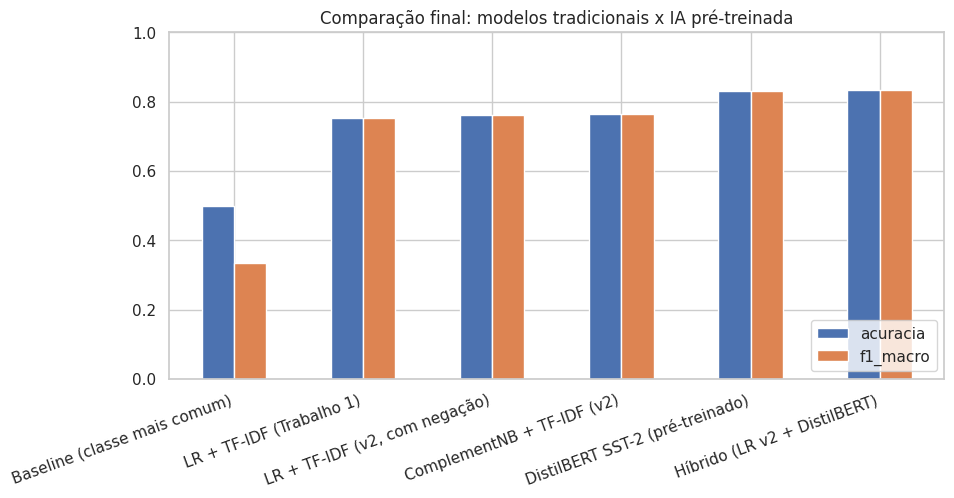

In [17]:
# [requer-HF]
import torch
from transformers import pipeline, AutoTokenizer, AutoModelForSeq2SeqLM

device = 0 if torch.cuda.is_available() else -1
print("Usando GPU" if device == 0 else "Usando CPU (pode levar alguns minutos)")

clf_hf = pipeline("text-classification", model="distilbert-base-uncased-finetuned-sst-2-english", device=device)


def p_fresh_hf(textos):
    saida = clf_hf(list(textos), batch_size=32, truncation=True, max_length=128)
    return np.array([s["score"] if s["label"] == "POSITIVE" else 1 - s["score"] for s in saida])


t0 = time.time()
textos_teste = df.loc[idx_teste, "review_content"].tolist()
p_hf = p_fresh_hf(textos_teste)
print(f"DistilBERT aplicado em {len(textos_teste)} críticas em {time.time() - t0:.0f}s")

registrar("DistilBERT SST-2 (pré-treinado)", np.where(p_hf >= 0.5, "Fresh", "Rotten"), p_hf)

p_hibrido = 0.5 * previsoes[NOME_V2][1] + 0.5 * p_hf
registrar("Híbrido (LR v2 + DistilBERT)", np.where(p_hibrido >= 0.5, "Fresh", "Rotten"), p_hibrido)

tabela_metricas = pd.DataFrame(metricas).set_index("modelo")
display(tabela_metricas.round(4))

fig, ax = plt.subplots(figsize=(10, 4.5))
tabela_metricas[["acuracia", "f1_macro"]].plot(kind="bar", ax=ax)
ax.set_ylim(0, 1)
ax.set_title("Comparação final: modelos tradicionais x IA pré-treinada")
ax.set_xlabel("")
plt.xticks(rotation=20, ha="right")
ax.legend(loc="lower right")
salvar_figura(fig, "v9_comparacao_final.png")
plt.show()

In [18]:
# [requer-HF] Demonstração ao vivo: classificar textos novos (troque pelos seus!)
textos_demo = [
    "A stunning, beautifully acted film. I loved every minute of it.",
    "Not good. The plot is boring and the acting is not convincing.",
    "It has its moments, but overall it is a disappointing mess.",
    "I expected to hate it, but it turned out to be surprisingly fun.",
]


def classificar_texto(textos):
    proc = processar_textos(textos)
    p_lr = modelo_v2.predict_proba(vet_v2.transform(proc))[:, IDX_FRESH]
    p_bert = p_fresh_hf(textos)
    return pd.DataFrame({"texto": textos, "P(Fresh) LR": p_lr.round(2), "P(Fresh) DistilBERT": p_bert.round(2),
                         "veredito híbrido": np.where((p_lr + p_bert) / 2 >= 0.5, "Fresh", "Rotten")})


display(classificar_texto(textos_demo))

,texto,P(Fresh) LR,P(Fresh) DistilBERT,veredito híbrido
0,"A stunning, beautifully acted film. I loved every minute of it.",0.86,1.0,Fresh
1,Not good. The plot is boring and the acting is not convincing.,0.07,0.0,Rotten
2,"It has its moments, but overall it is a disappointing mess.",0.06,0.0,Rotten
3,"I expected to hate it, but it turned out to be surprisingly fun.",0.84,1.0,Fresh


**7.2 Modelo generativo (Flan-T5) para escrever o perfil do crítico.**
O modelo recebe **somente os fatos calculados** na Seção 6 (gêneros com maior/menor lift, filmes recomendados) e redige o texto.
Como modelos pequenos podem inventar coisas, mostramos **sempre os fatos e um texto-modelo determinístico** ao lado do texto gerado.

In [19]:
# [requer-HF]
MODELO_GERADOR = "google/flan-t5-base"      # para texto melhor (e mais lento): "google/flan-t5-large"
tok_gen = AutoTokenizer.from_pretrained(MODELO_GERADOR)
mod_gen = AutoModelForSeq2SeqLM.from_pretrained(MODELO_GERADOR)
if torch.cuda.is_available():
    mod_gen = mod_gen.to("cuda")


def gerar_texto(prompt, max_new_tokens=120):
    entradas = tok_gen(prompt, return_tensors="pt", truncation=True, max_length=512)
    entradas = {k: v.to(mod_gen.device) for k, v in entradas.items()}
    saida = mod_gen.generate(**entradas, max_new_tokens=max_new_tokens, num_beams=4,
                             no_repeat_ngram_size=3, early_stopping=True)
    return tok_gen.decode(saida[0], skip_special_tokens=True)


print("Gerador carregado:", MODELO_GERADOR)

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Gerador carregado: google/flan-t5-base


In [20]:
def montar_fatos(nome, perfil, base, recs):
    p = perfil[perfil["n"] >= 5]
    if len(p) < 4:
        p = perfil[perfil["n"] >= 3]
    gosta = p.head(3)
    desgosta = p.tail(3).iloc[::-1]
    f_gosta = "; ".join(f"{g} ({r.lift * 100:+.0f} points, {int(r.n)} reviews)" for g, r in gosta.iterrows())
    f_desgosta = "; ".join(f"{g} ({r.lift * 100:+.0f} points, {int(r.n)} reviews)" for g, r in desgosta.iterrows())
    f_recs = "; ".join(recs["movie_title"].tolist())
    return (f"Critic: {nome}. Share of positive reviews: {base * 100:.0f}%. "
            f"Genres liked more than usual: {f_gosta}. Genres liked less than usual: {f_desgosta}. "
            f"Recommended movies: {f_recs}.")


def relatorio_critico(nome, coluna="rotulo_previsto", top_n=5, usar_ia=True):
    recs, perfil, base = recomendar_filmes(nome, coluna, top_n)
    fatos = montar_fatos(nome, perfil, base, recs)

    print("=" * 80)
    print(f"CRÍTICO: {nome}   (rótulos usados no perfil: {'previstos pelo modelo' if coluna == 'rotulo_previsto' else 'reais'})")
    print("=" * 80)
    print("\n1) Perfil de gêneros (lift = quanto gosta acima/abaixo da própria média):")
    display(perfil[perfil["n"] >= 5][["n", "taxa_bruta", "afinidade", "lift"]].round(3))
    print("2) Filmes recomendados (ainda não avaliados por ele):")
    display(recs.round(3))
    print("3) Fatos entregues à IA:\n  ", fatos)
    print("\n4) Texto-modelo (determinístico):")
    p = perfil[perfil["n"] >= 5]
    print(f"   {nome} avalia positivamente {base:.0%} das críticas. "
          f"Gosta mais de: {', '.join(p.head(3).index)}. Gosta menos de: {', '.join(p.tail(3).iloc[::-1].index)}.")
    if usar_ia:
        prompt = ("Using only the facts below, write two short sentences describing the movie taste of this film critic "
                  "and what kind of films to recommend.\n\nFacts: " + fatos + "\n\nDescription:")
        print("\n5) Texto gerado pela IA (Flan-T5):\n  ", gerar_texto(prompt))
    return recs

In [21]:
# [requer-HF] escolha o crítico (por padrão, o que mais avaliou filmes no corpus)
nome_critico = contagem_criticos.index[0]
_ = relatorio_critico(nome_critico, coluna="rotulo_previsto", usar_ia=True)

CRÍTICO: Frank Swietek   (rótulos usados no perfil: previstos pelo modelo)

1) Perfil de gêneros (lift = quanto gosta acima/abaixo da própria média):


,n,taxa_bruta,afinidade,lift
genero,,,,
Art House & International,17,0.647,0.569,0.264
Documentary,6,0.667,0.503,0.197
Special Interest,6,0.667,0.503,0.197
Animation,7,0.571,0.461,0.155
Musical & Performing Arts,6,0.500,0.412,0.106
Comedy,54,0.389,0.382,0.076
Kids & Family,13,0.385,0.363,0.057
Science Fiction & Fantasy,22,0.364,0.353,0.047
Drama,93,0.344,0.342,0.036


2) Filmes recomendados (ainda não avaliados por ele):


,movie_title,genres,tomatometer_rating,afinidade,score
21923,United We Fan,"Art House & International, Documentary",100.0,0.536,0.675
7928,"Faces Places (Visages, villages)","Art House & International, Documentary",99.0,0.536,0.672
10102,Last Train Home,"Art House & International, Documentary, Special Interest",100.0,0.525,0.667
15227,Rio Breaks,"Art House & International, Documentary, Special Interest",100.0,0.525,0.667
21060,Modern Life (Profils paysans: la vie moderne),"Art House & International, Documentary, Special Interest",100.0,0.525,0.667


3) Fatos entregues à IA:
   Critic: Frank Swietek. Share of positive reviews: 31%. Genres liked more than usual: Art House & International (+26 points, 17 reviews); Documentary (+20 points, 6 reviews); Special Interest (+20 points, 6 reviews). Genres liked less than usual: Horror (-11 points, 13 reviews); Mystery & Suspense (-9 points, 39 reviews); Action & Adventure (-4 points, 39 reviews). Recommended movies: United We Fan; Faces Places (Visages, villages); Last Train Home; Rio Breaks; Modern Life (Profils paysans: la vie moderne).

4) Texto-modelo (determinístico):
   Frank Swietek avalia positivamente 31% das críticas. Gosta mais de: Art House & International, Documentary, Special Interest. Gosta menos de: Horror, Mystery & Suspense, Action & Adventure.

5) Texto gerado pela IA (Flan-T5):
   Frank Swietek rated Art House & International with 31%.


## 8. Resumo dos resultados e arquivos gerados

In [22]:
tabela_metricas = pd.DataFrame(metricas).set_index("modelo")
tabela_metricas.round(4).to_csv(raiz / "resultados" / "metricas_modelos.csv")
tabela_rec.round(4).to_csv(raiz / "resultados" / "metricas_recomendador.csv")
perfil_exemplo.round(4).to_csv(raiz / "resultados" / "perfil_critico_exemplo.csv")
recs_exemplo.round(4).to_csv(raiz / "resultados" / "recomendacoes_exemplo.csv", index=False)
resumo = {
    "n_criticas": int(len(df)), "n_criticos_elegiveis": int(len(criticos_elegiveis)),
    "correlacao_perfil_real_vs_previsto": round(corr_media, 3),
    "auc_recomendador_rotulos_reais": {k: round(v, 3) for k, v in auc_real.items()},
    "auc_recomendador_rotulos_previstos": {k: round(v, 3) for k, v in auc_prev.items()},
}
with open(raiz / "resultados" / "resumo.json", "w", encoding="utf-8") as f:
    json.dump(resumo, f, ensure_ascii=False, indent=2)

print("RESUMO (copie esta saída para montar o relatório e a apresentação)")
print("-" * 70)
print(tabela_metricas.round(4).to_string())
print()
print(json.dumps(resumo, ensure_ascii=False, indent=2))
print("\nArquivos em", raiz / "resultados", ":")
for arq in sorted((raiz / "resultados").glob("*")):
    print(" -", arq.name)

RESUMO (copie esta saída para montar o relatório e a apresentação)
----------------------------------------------------------------------
                                 acuracia  f1_macro     auc
modelo                                                     
Baseline (classe mais comum)       0.5000    0.3333  0.5000
LR + TF-IDF (Trabalho 1)           0.7540    0.7539  0.8315
LR + TF-IDF (v2, com negação)      0.7610    0.7610  0.8391
ComplementNB + TF-IDF (v2)         0.7638    0.7637  0.8406
DistilBERT SST-2 (pré-treinado)    0.8306    0.8306  0.9095
Híbrido (LR v2 + DistilBERT)       0.8333    0.8333  0.9027

{
  "n_criticas": 23999,
  "n_criticos_elegiveis": 309,
  "correlacao_perfil_real_vs_previsto": 0.511,
  "auc_recomendador_rotulos_reais": {
    "tomatometer": 0.829,
    "afinidade": 0.633,
    "lift": 0.582,
    "combinado": 0.788
  },
  "auc_recomendador_rotulos_previstos": {
    "tomatometer": 0.829,
    "afinidade": 0.592,
    "lift": 0.555,
    "combinado": 0.774
  }
}

Ar

### Conclusões (preencher com os números reais da execução)

- **Classificação:** compare baseline, pipeline do Trabalho 1, pipeline v2 e Naive Bayes — manter a negação ajudou?
- **IA pré-treinada:** o DistilBERT, sem treino, ficou acima ou abaixo do modelo treinado no nosso corpus? O híbrido melhorou?
- **Recomendação:** o gosto por gênero (AUC do *lift*) acrescenta algo além da qualidade global do filme (*tomatometer*)?
- **Rótulos previstos vs. reais:** o texto sozinho é suficiente para montar o perfil do crítico?
- **Limitações:** ruído de rótulo, amostra balanceada artificialmente, trechos curtos, catálogo restrito, poucos filmes por crítico, risco de o modelo generativo "inventar" detalhes.
- **Trabalho futuro:** embeddings contextuais (sentence-transformers) para recomendar por similaridade de texto, ajuste fino (*fine-tuning*) do DistilBERT, e uso de notas numéricas (`review_score`) em vez de só *Fresh/Rotten*.